<a href="https://colab.research.google.com/github/eriksetiawan018-Maverick/Erik-Setiawan-UAS-ADKP-Electrical-Safety-/blob/main/Erik%20Setiawan-Uas%20ADKP%20Electrical%20Safety%20Monte%20Carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Erik Setiawan-Uas ADKP Electrical Safety Monte Carlo

## Prediksi Skor Risiko Keselamatan Listrik + Simulasi Monte Carlo

**UAS ADKP — Model Regresi + Monte Carlo**

Notebook ini membangun **model regresi** untuk memprediksi `Electrical_Safety_Risk_Score` (skor risiko keselamatan listrik, skala 0–100) dari data pekerjaan listrik di data center, lalu memakai model terbaik di dalam **simulasi Monte Carlo** untuk menjawab pertanyaan *what-if*, misalnya:

- Berapa persen pekerjaan yang masuk kategori risiko **Medium/High** dalam kondisi sekarang?
- Apa yang terjadi kalau semua pekerjaan dilakukan saat **shift malam**?
- Seberapa besar risiko turun kalau **pelanggaran LOTO dihilangkan** atau **kelelahan pekerja dikurangi**?

**Alur:**
1. Memuat data
2. Eksplorasi data (EDA)
3. Pembersihan & pemilihan fitur (termasuk membuang kolom yang "bocor")
4. Melatih dan membandingkan model regresi
5. Faktor yang paling berpengaruh
6. Simulasi Monte Carlo skenario what-if
7. Kesimpulan

## 1. Memuat data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
# Dataset: electrical_safety_5000.csv (Kaggle)
# Di Google Colab: upload file CSV lewat panel Files, atau jalankan sel ini dan pilih file saat diminta.
DATA_PATH = "electrical_safety_5000.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files  # hanya ada di Colab
        uploaded = files.upload()
        DATA_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("Taruh electrical_safety_5000.csv di folder yang sama dengan notebook ini.")

df = pd.read_csv(DATA_PATH)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (5000, 200)


,Incident_ID,Incident_Date,Incident_Time,Site_ID,Building_ID,Data_Hall,Power_Cell,Tile,Rack,Incident_Type,Incident_Category,Near_Miss_Flag,Injury_Occurred,Injury_Severity,Medical_Treatment_Required,Lost_Time_Incident,Fatality_Flag,Equipment_Damage,Service_Impact,Root_Cause,Corrective_Action,Incident_Occurred_Target,Employee_ID,Role,Organization,...,Days_Since_Last_Incident,Days_Since_Last_NearMiss,Incident_Description,Investigation_Notes,Corrective_Action_Text,Lessons_Learned,Root_Cause_Text,NLP_Human_Error_Score,NLP_Procedure_Violation_Score,NLP_Equipment_Failure_Score,NLP_LOTO_Risk_Score,NLP_Safety_Culture_Score,Safety_Compliance_Index,Equipment_Health_Index,Employee_Risk_Index,Electrical_Exposure_Score,Fatigue_Index,Environmental_Risk_Index,Training_Effectiveness_Score,Predictive_Risk_Score,Electrical_Incident_Occurred,Electrical_Incident_Severity,Risk_Level,Probability_of_Incident,Electrical_Safety_Risk_Score
0,INC00000,4/25/2025,0:47,DC4,B2,DH3,PC6,T177,R72,Shock,Electrical,0,0,NaN,0,0,0,0,0,Equipment aging,Update SOP and checklist,1,EMP801,Engineer,Contractor,...,22,235,Shock incident during electrical work.,Detailed investigation performed by safety team.,Update SOP and checklist,Need for better fatigue management,Equipment aging,0.72,0.28,0.26,0.38,0.90,88.1,85.7,39.6,50.6,75.5,31.1,70.4,45.63,1,Low,Medium,0.907,45.63
1,INC00001,2/27/2025,7:52,DC4,B1,DH1,PC3,T79,R31,Fire,Electrical,0,1,Low,1,0,0,1,0,Inadequate PPE,Reinforce LOTO training,1,EMP346,Supervisor,Contractor,...,365,365,Fire incident during electrical work.,Detailed investigation performed by safety team.,Reinforce LOTO training,Critical role of THA before energized work,Inadequate PPE,0.66,0.32,0.78,0.16,0.79,84.4,94.2,35.3,45.3,75.7,26.1,100.0,28.02,1,Low,Low,0.802,28.02
2,INC00002,3/29/2025,23:31,DC4,B1,DH1,PC4,T141,R13,Arc Flash,Electrical,0,1,Low,0,1,0,1,0,LOTO failure,Update SOP and checklist,1,EMP767,Engineer,Full-Time,...,365,323,Arc Flash incident during electrical work.,Detailed investigation performed by safety team.,Update SOP and checklist,Critical role of THA before energized work,LOTO failure,1.00,0.31,0.70,0.30,0.68,89.4,100.0,28.4,33.5,59.9,32.9,61.8,39.41,1,Low,Low,0.878,39.41
3,INC00003,4/6/2025,7:10,DC1,B1,DH3,PC3,T41,R57,Arc Flash,Operational,0,0,NaN,0,0,0,1,1,Procedure violation,Update SOP and checklist,1,EMP726,Operator,Full-Time,...,95,35,Arc Flash incident during electrical work.,Detailed investigation performed by safety team.,Update SOP and checklist,Critical role of THA before energized work,Procedure violation,0.92,0.71,0.20,0.25,0.89,91.0,78.5,30.3,44.2,61.3,29.4,65.4,47.15,1,Low,Medium,0.914,47.15
4,INC00004,11/3/2025,21:06,DC3,B1,DH1,PC4,T10,R61,Shock,Electrical,0,0,NaN,0,0,0,1,0,Procedure violation,Conduct targeted safety briefing,1,EMP304,Engineer,Full-Time,...,57,38,Shock incident during electrical work.,Detailed investigation performed by safety team.,Conduct targeted safety briefing,Need for better fatigue management,Procedure violation,0.41,0.73,0.66,0.36,0.79,83.7,96.0,23.3,22.3,49.7,28.5,83.4,20.89,1,Low,Low,0.740,20.89


## 2. Eksplorasi data (EDA)

In [3]:
TARGET = "Electrical_Safety_Risk_Score"

print("Jumlah baris duplikat:", df.duplicated().sum())
missing = df.isna().sum()
print("Kolom dengan data kosong:")
print(missing[missing > 0])
print()
print(df[TARGET].describe())

Jumlah baris duplikat: 0
Kolom dengan data kosong:
Injury_Severity                 3302
Electrical_Incident_Severity     650
dtype: int64

count    5000.000000
mean       39.856706
std        10.457604
min         4.460000
25%        32.580000
50%        39.600000
75%        46.905000
max        83.030000
Name: Electrical_Safety_Risk_Score, dtype: float64


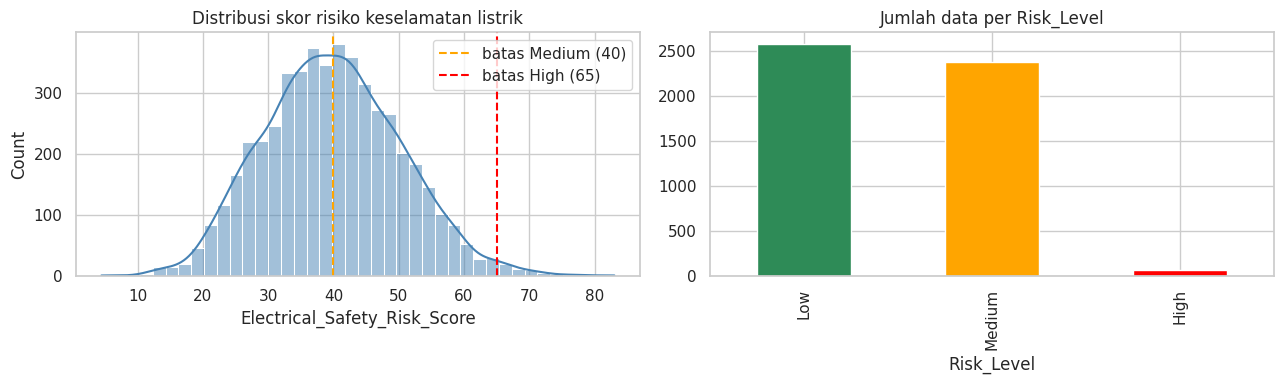

,min,max,count
Risk_Level,,,
High,65.04,83.03,60
Low,4.46,40.00,2573
Medium,40.00,64.90,2367


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df[TARGET], bins=40, kde=True, ax=ax[0], color="steelblue")
ax[0].axvline(40, color="orange", ls="--", label="batas Medium (40)")
ax[0].axvline(65, color="red", ls="--", label="batas High (65)")
ax[0].set_title("Distribusi skor risiko keselamatan listrik")
ax[0].legend()

df["Risk_Level"].value_counts().reindex(["Low", "Medium", "High"]).plot.bar(ax=ax[1], color=["seagreen", "orange", "red"])
ax[1].set_title("Jumlah data per Risk_Level")
plt.tight_layout(); plt.show()

# Risk_Level ternyata hanya potongan dari skor: <40 Low, 40–65 Medium, >65 High
df.groupby("Risk_Level")[TARGET].agg(["min", "max", "count"])

In [5]:
# Korelasi kolom numerik dengan target
num_corr = df.select_dtypes("number").corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
num_corr.head(15)

,Electrical_Safety_Risk_Score
Predictive_Risk_Score,1.000000
Probability_of_Incident,0.969342
Night_Shift_Flag,0.533795
Initial_Risk_Score,0.463854
Equipment_Health_Score,-0.419504
Equipment_Health_Index,-0.419504
Fatigue_Index,0.400233
Fatigue_Score,0.400233
Residual_Risk_Score,0.379346
Equipment_Age_Years,0.369213


**Temuan penting dari EDA:**
- Data bersih: tidak ada duplikat; kolom kosong hanya `Injury_Severity` dan `Electrical_Incident_Severity` (kosong karena memang tidak ada cedera/insiden).
- `Predictive_Risk_Score` berkorelasi **1,0** dan `Probability_of_Incident` **0,97** dengan target. Kolom ini kemungkinan dihitung dari target (atau sebaliknya), jadi kalau dipakai sebagai fitur, model akan "nyontek" (*data leakage*). Keduanya **dibuang**.
- `Risk_Level` hanyalah hasil potong skor (Low < 40, Medium 40–65, High > 65), jadi juga dibuang dari fitur, tapi batasnya dipakai lagi di simulasi Monte Carlo.
- Distribusi kategori sangat merata, sehingga dataset ini kemungkinan besar **data sintetis**. Hasil model menggambarkan pola di data ini, bukan kondisi data center nyata.

## 3. Pembersihan & pemilihan fitur

In [6]:
# (a) Kolom yang bocor / turunan langsung dari target atau hasil insiden (terjadi SETELAH kejadian)
leak_cols = [
    TARGET, "Predictive_Risk_Score", "Probability_of_Incident", "Risk_Level",
    "Electrical_Incident_Occurred", "Electrical_Incident_Severity", "Incident_Occurred_Target",
    "Near_Miss_Flag", "Injury_Occurred", "Injury_Severity", "Medical_Treatment_Required",
    "Lost_Time_Incident", "Fatality_Flag", "Equipment_Damage", "Service_Impact",
    "Incident_Type", "Incident_Category", "Root_Cause", "Corrective_Action",
]
# (b) Kolom ID, tanggal, jam, dan teks bebas (tidak bermakna sebagai fitur)
id_cols = [c for c in df.columns if c.endswith("_ID") or c in ["Serial_Number", "Model", "Tile", "Rack"]]
date_cols = [c for c in df.columns if c.endswith("_Date") or c.endswith("_Time")]
text_cols = ["Incident_Description", "Investigation_Notes", "Corrective_Action_Text", "Lessons_Learned", "Root_Cause_Text"]
# (c) Kolom yang nilainya sama semua
const_cols = [c for c in df.columns if df[c].nunique() <= 1]
# (d) Indeks gabungan yang dihitung dari kolom mentah lain, misalnya:
#     Fatigue_Index = Fatigue_Score (identik), Equipment_Health_Index = Equipment_Health_Score (identik),
#     Electrical_Exposure_Score ~ UPS_Load_Percent (korelasi 1,0), Employee_Risk_Index ~ Fatigue_Score (0,94),
#     Environmental_Risk_Index ~ Cooling_Utilization_Percent (0,89).
#     Apparent_Power_kVA, Active_Power_kW, Reactive_Power_kVAR dihitung dari Voltage, Current, Power_Factor
#     (Current vs Apparent_Power_kVA korelasi 1,0), sehingga bikin model linear tidak stabil (multikolinearitas).
#     Dibuang supaya model memakai variabel mentah yang bisa diubah langsung di simulasi Monte Carlo.
dup_cols = ["Fatigue_Index", "Equipment_Health_Index", "Electrical_Exposure_Score", "Employee_Risk_Index",
            "Environmental_Risk_Index", "Safety_Compliance_Index", "Training_Effectiveness_Score",
            "Apparent_Power_kVA", "Active_Power_kW", "Reactive_Power_kVAR"]

drop_cols = set(leak_cols + id_cols + date_cols + text_cols + const_cols + dup_cols)
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df[TARGET]

cat_features = X.select_dtypes(exclude="number").columns.tolist()
num_features = X.select_dtypes("number").columns.tolist()
print(f"Fitur numerik: {len(num_features)}, fitur kategorik: {len(cat_features)}")
print("Fitur kategorik:", cat_features)

Fitur numerik: 120, fitur kategorik: 19
Fitur kategorik: ['Data_Hall', 'Power_Cell', 'Role', 'Organization', 'Work_Type', 'Equipment_Criticality', 'Initial_Severity', 'Initial_Likelihood', 'Residual_Severity', 'Residual_Likelihood', 'Permit_Type', 'Permit_Approver', 'Equipment_Type', 'Manufacturer', 'Warranty_Status', 'Breaker_Type', 'Weather_Condition', 'Auditor', 'Audit_Type']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

Train: (4000, 139)  Test: (1000, 139)


## 4. Melatih dan membandingkan model regresi

Empat model dibandingkan:
- **Linear Regression**: baseline paling sederhana dan mudah diinterpretasi.
- **Ridge Regression**: regresi linear dengan regularisasi (mencegah overfitting karena fiturnya banyak).
- **Random Forest**: kumpulan pohon keputusan, bisa menangkap pola non-linear.
- **Gradient Boosting** (HistGradientBoosting): pohon yang dibangun bertahap untuk memperbaiki kesalahan sebelumnya.

Metrik: **MAE** (rata-rata selisih absolut), **RMSE** (menghukum kesalahan besar), dan **R²** (proporsi variasi yang dijelaskan model, makin dekat 1 makin baik). Selain test set, dipakai juga **5-fold cross validation** pada data train.

In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=SEED),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2", n_jobs=-1)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({
        "Model": name,
        "CV R2 (train)": cv_r2.mean(),
        "MAE (test)": mean_absolute_error(y_test, pred),
        "RMSE (test)": np.sqrt(mean_squared_error(y_test, pred)),
        "R2 (test)": r2_score(y_test, pred),
    })

results = pd.DataFrame(results).sort_values("R2 (test)", ascending=False).reset_index(drop=True)
results.round(3)

,Model,CV R2 (train),MAE (test),RMSE (test),R2 (test)
0,Ridge Regression,0.753,4.049,5.085,0.772
1,Linear Regression,0.752,4.051,5.086,0.772
2,Gradient Boosting,0.730,4.125,5.193,0.762
3,Random Forest,0.699,4.315,5.471,0.736


Model terbaik: Ridge Regression


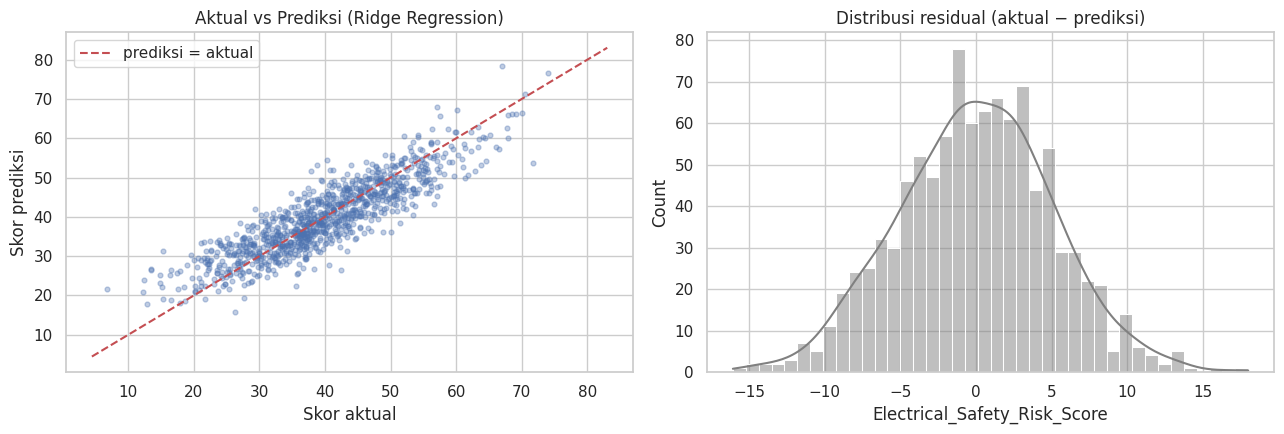

Standar deviasi residual: 5.09 poin


In [9]:
best_name = results.loc[0, "Model"]
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)
print("Model terbaik:", best_name)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y_test, y_pred, alpha=0.35, s=12)
lims = [y.min(), y.max()]
ax[0].plot(lims, lims, "r--", label="prediksi = aktual")
ax[0].set_xlabel("Skor aktual"); ax[0].set_ylabel("Skor prediksi")
ax[0].set_title(f"Aktual vs Prediksi ({best_name})"); ax[0].legend()

residuals = y_test - y_pred
sns.histplot(residuals, bins=40, kde=True, ax=ax[1], color="gray")
ax[1].set_title("Distribusi residual (aktual − prediksi)")
plt.tight_layout(); plt.show()
print(f"Standar deviasi residual: {residuals.std():.2f} poin")

## 5. Faktor yang paling berpengaruh

Dipakai **permutation importance**: nilai satu fitur diacak, lalu dilihat seberapa besar R² model turun. Makin besar penurunannya, makin penting fitur tersebut. Cara ini berlaku untuk model apa pun.

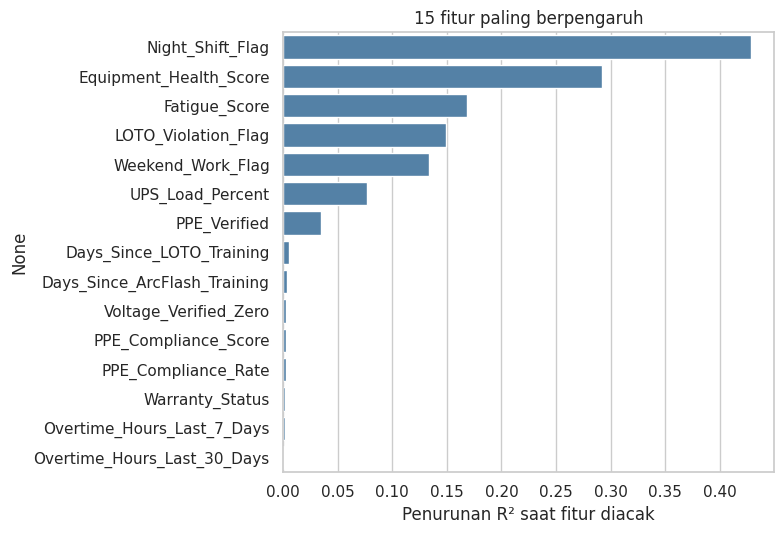

,0
Night_Shift_Flag,0.4281
Equipment_Health_Score,0.2922
Fatigue_Score,0.1683
LOTO_Violation_Flag,0.1496
Weekend_Work_Flag,0.1334
UPS_Load_Percent,0.0767
PPE_Verified,0.0346
Days_Since_LOTO_Training,0.0051
Days_Since_ArcFlash_Training,0.0039
Voltage_Verified_Zero,0.0028


In [10]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=5, random_state=SEED, n_jobs=-1, scoring="r2")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

top = imp.head(15)
plt.figure(figsize=(8, 5.5))
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.xlabel("Penurunan R² saat fitur diacak")
plt.title("15 fitur paling berpengaruh")
plt.tight_layout(); plt.show()
top.round(4)

In [11]:
N_SAMPLES = 5000   # pekerjaan per simulasi
N_RUNS = 200       # pengulangan per skenario
MEDIUM_T, HIGH_T = 40, 65
rng = np.random.default_rng(SEED)

# residual dari data test dipakai sebagai sumber noise ketidakpastian model
resid_pool = (y_test - best_model.predict(X_test)).values

def fatigue_down(d, pct=0.2):
    d["Fatigue_Score"] = d["Fatigue_Score"] * (1 - pct)
    return d

def equipment_better(d, pts=10):
    d["Equipment_Health_Score"] = np.clip(d["Equipment_Health_Score"] + pts, 0, 100)
    return d

scenarios = {
    "Baseline (kondisi sekarang)": lambda d: d,
    "Semua shift malam":           lambda d: d.assign(Night_Shift_Flag=1),
    "Tanpa shift malam":           lambda d: d.assign(Night_Shift_Flag=0),
    "Kelelahan turun 20%":         fatigue_down,
    "Kesehatan alat +10 poin":     equipment_better,
    "LOTO 100% patuh":             lambda d: d.assign(LOTO_Violation_Flag=0),
    "Kombinasi perbaikan":         lambda d: equipment_better(fatigue_down(d.assign(Night_Shift_Flag=0, LOTO_Violation_Flag=0))),
}

def run_scenario(modifier):
    stats = []
    for _ in range(N_RUNS):
        idx = rng.integers(0, len(X), N_SAMPLES)
        sample = modifier(X.iloc[idx].copy())
        score = best_model.predict(sample) + rng.choice(resid_pool, N_SAMPLES)
        score = np.clip(score, 0, 100)
        stats.append((score.mean(), (score >= MEDIUM_T).mean(), (score > HIGH_T).mean()))
    return np.array(stats), score   # score terakhir disimpan untuk plot distribusi

mc_stats, mc_last = {}, {}
for name, mod in scenarios.items():
    mc_stats[name], mc_last[name] = run_scenario(mod)
print("Simulasi selesai:", len(scenarios), "skenario x", N_RUNS, "run x", N_SAMPLES, "pekerjaan")

Simulasi selesai: 7 skenario x 200 run x 5000 pekerjaan


## 6. Simulasi Monte Carlo: skenario *what-if*

Model regresi hanya memprediksi skor untuk satu pekerjaan. Dengan **Monte Carlo**, kita mensimulasikan ribuan pekerjaan acak untuk melihat **distribusi** risiko dan **peluang** sebuah pekerjaan masuk kategori Medium/High pada berbagai skenario.

**Cara kerja satu kali simulasi (satu skenario):**
1. Ambil `N = 5.000` pekerjaan secara acak *dengan pengembalian* (bootstrap) dari data. Ini menjaga hubungan antar-variabel tetap realistis.
2. Ubah variabel sesuai skenario (misalnya `Night_Shift_Flag = 1` untuk semua).
3. Prediksi skor dengan model terbaik.
4. Tambahkan **noise acak** dari distribusi residual model, karena model tidak sempurna (ketidakpastian model ikut disimulasikan).
5. Hitung rata-rata skor, `P(skor ≥ 40)` (Medium ke atas), dan `P(skor > 65)` (High).

Langkah 1–5 diulang `R = 200` kali per skenario, sehingga kita mendapat **rata-rata dan interval kepercayaan 95%** untuk setiap angka.

In [12]:
def ci(a):
    return f"{np.mean(a):.2f} [{np.percentile(a, 2.5):.2f} – {np.percentile(a, 97.5):.2f}]"

def ci_pct(a):
    return f"{100*np.mean(a):.1f}% [{100*np.percentile(a, 2.5):.1f} – {100*np.percentile(a, 97.5):.1f}]"

base_mean = mc_stats["Baseline (kondisi sekarang)"][:, 0].mean()
summary = pd.DataFrame({
    name: {
        "Rata-rata skor [CI 95%]": ci(s[:, 0]),
        "Perubahan vs baseline": f"{s[:, 0].mean() - base_mean:+.2f}",
        "P(Medium/High, skor ≥ 40)": ci_pct(s[:, 1]),
        "P(High, skor > 65)": ci_pct(s[:, 2]),
    } for name, s in mc_stats.items()
}).T
summary

,Rata-rata skor [CI 95%],Perubahan vs baseline,"P(Medium/High, skor ≥ 40)","P(High, skor > 65)"
Baseline (kondisi sekarang),39.84 [39.55 – 40.13],+0.00,48.0% [46.5 – 49.3],1.2% [0.8 – 1.5]
Semua shift malam,45.07 [44.85 – 45.31],+5.23,70.9% [69.6 – 72.3],2.0% [1.7 – 2.4]
Tanpa shift malam,35.37 [35.14 – 35.61],-4.47,28.7% [27.5 – 29.8],0.2% [0.1 – 0.3]
Kelelahan turun 20%,36.78 [36.52 – 37.05],-3.06,36.6% [35.4 – 37.9],0.6% [0.4 – 0.8]
Kesehatan alat +10 poin,37.49 [37.27 – 37.76],-2.35,39.2% [37.9 – 40.4],0.7% [0.5 – 0.9]
LOTO 100% patuh,39.19 [38.93 – 39.45],-0.65,46.1% [44.6 – 47.5],0.5% [0.3 – 0.7]
Kombinasi perbaikan,29.30 [29.06 – 29.52],-10.54,9.1% [8.3 – 10.0],0.0% [0.0 – 0.0]


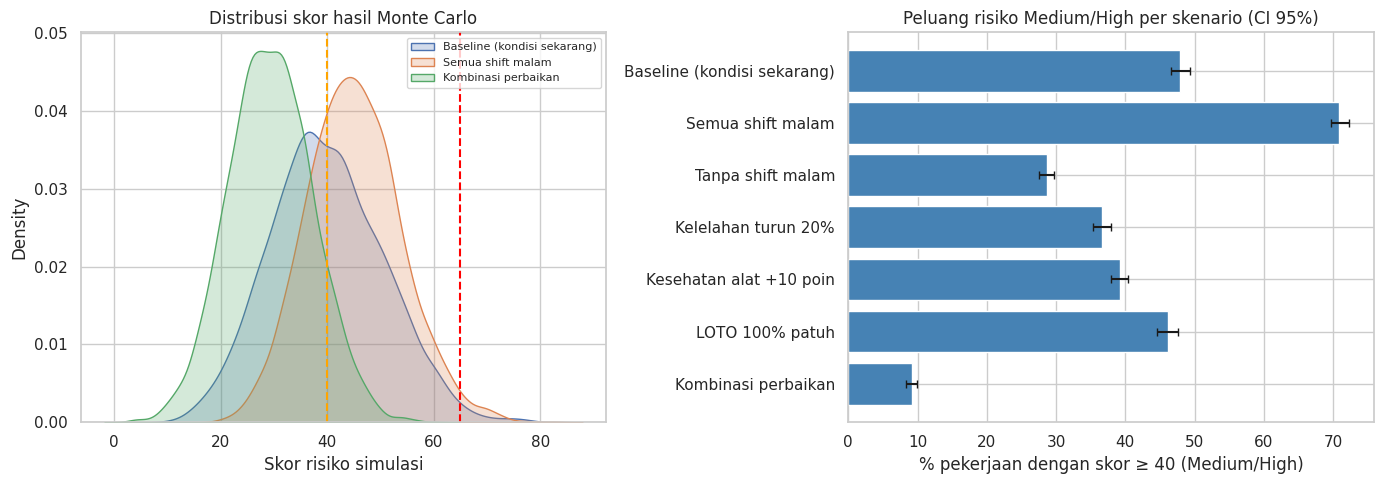

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name in ["Baseline (kondisi sekarang)", "Semua shift malam", "Kombinasi perbaikan"]:
    sns.kdeplot(mc_last[name], ax=ax[0], label=name, fill=True, alpha=0.25)
ax[0].axvline(MEDIUM_T, color="orange", ls="--"); ax[0].axvline(HIGH_T, color="red", ls="--")
ax[0].set_xlabel("Skor risiko simulasi"); ax[0].set_title("Distribusi skor hasil Monte Carlo")
ax[0].legend(fontsize=8)

names = list(mc_stats.keys())
p_med = [100 * mc_stats[n][:, 1].mean() for n in names]
err = [[100 * (mc_stats[n][:, 1].mean() - np.percentile(mc_stats[n][:, 1], 2.5)) for n in names],
       [100 * (np.percentile(mc_stats[n][:, 1], 97.5) - mc_stats[n][:, 1].mean()) for n in names]]
ax[1].barh(names, p_med, xerr=err, color="steelblue", capsize=3)
ax[1].invert_yaxis()
ax[1].set_xlabel("% pekerjaan dengan skor ≥ 40 (Medium/High)")
ax[1].set_title("Peluang risiko Medium/High per skenario (CI 95%)")
plt.tight_layout(); plt.show()

## 7. Kesimpulan

*(Angka di bawah dari hasil run dengan `SEED = 42`; kalau dijalankan ulang hasilnya sama atau beda sangat tipis.)*

- **Model regresi:** Ridge Regression dan Linear Regression jadi model terbaik dengan **R² ≈ 0,77** dan **MAE ≈ 4 poin** di data test, sedikit lebih baik dari Gradient Boosting (0,76) dan Random Forest (0,74). Artinya hubungan faktor risiko dengan skor di dataset ini sebagian besar linear, jadi model sederhana sudah cukup dan lebih mudah dijelaskan.
- **Faktor paling berpengaruh:** shift malam, kesehatan peralatan, tingkat kelelahan pekerja, pelanggaran LOTO, kerja di akhir pekan, dan beban UPS.
- **Simulasi Monte Carlo** (7 skenario × 200 run × 5.000 pekerjaan):
  - Kondisi sekarang: rata-rata skor ≈ 39,8 dan sekitar **48%** pekerjaan berisiko Medium/High.
  - Kalau semua pekerjaan dilakukan saat shift malam, angkanya naik ke sekitar **71%**. Kalau shift malam dihindari, turun ke sekitar **29%**.
  - Kelelahan turun 20% menurunkan peluang Medium/High ke sekitar **37%**, kesehatan alat +10 poin ke sekitar **39%**, sedangkan LOTO 100% patuh efeknya kecil (sekitar **46%**) karena pelanggaran LOTO di data cuma 4%.
  - **Kombinasi perbaikan** (tanpa shift malam, kelelahan turun, alat lebih sehat, LOTO patuh) menurunkan peluang Medium/High ke sekitar **9%** dan risiko High hampir nol.
- Interval kepercayaan 95% yang sempit menunjukkan hasil simulasi stabil, dan ketidakpastian model (residual) sudah ikut dihitung.

**Keterbatasan:**
- Dataset kemungkinan besar sintetis, jadi angka-angka di sini menggambarkan pola dalam data, bukan bukti kausal di data center nyata.
- Skenario mengubah satu variabel tanpa mengubah variabel lain yang mungkin ikut berubah di dunia nyata (misalnya shift malam bisa ikut menaikkan kelelahan).
- Batas kategori (40 dan 65) diambil dari kolom `Risk_Level` di dataset.